## Group 1.3 — Heavy-Tailed Label Corruption
> Compare SmallMLP and XGBoost under Cauchy contamination of regression targets. A separate binary-classification experiment compares SmallGBM and XGBoost under label flips; numeric Cauchy noise is not applied to class labels. Requires installed numpy, scipy, scikit-learn, torch, xgboost, matplotlib, smallmlp, and smallgbm. Run all cells in order. No package installation or source compilation is performed. Package versions and results are saved under results/group13/<run>/.


In [1]:
import csv
import ctypes
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import make_friedman1
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score
from smallgbm import SmallGBMClassifier
from smallgbm import tree as gbm_tree
from smallmlp import SmallMLPRegressor
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier, XGBRegressor

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

# SmallGBM 1.5.0 uses C rand(); random_state alone does not seed it.
# Fits must run sequentially. C random streams can differ between platforms.
seed_c = gbm_tree._lib.srand
seed_c.argtypes = [ctypes.c_uint]
seed_c.restype = None

## Protocol
- 300 training rows, 10 features, 5,000 independent test rows, and 10 fixed seeds.
- Corruption rates: 0%, 1%, 5%, 10%, and 20% (0, 3, 15, 30, and 60 labels).
- Cauchy scale: the IQR of clean training targets, used only by the corruption generator. Models receive corrupted targets. No clipping or resampling of extreme draws.
- Each seed uses nested corruption masks and identical data across models. The clean test is shared across seeds and never used for fitting or selection.
- SmallMLP retains its internal 20% validation split and default early stopping. XGBoost uses the fixed settings below; these are not library defaults.

N_TRAIN, N_TEST, N_FEATURES = 300, 5000, 10
RATES = (0.00, 0.01, 0.05, 0.10, 0.20)
SEEDS = (11, 29, 47, 71, 101, 131, 173, 211, 257, 307)
CAUCHY_SCALE_MULTIPLIER = 1.0
RUN_CLASSIFICATION = True

OUT = Path("results/group13") / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "data").mkdir()
(OUT / "predictions").mkdir()

print(f"Corrupted labels per rate: {[round(p * N_TRAIN) for p in RATES]}")
print(f"Results: {OUT}")

In [3]:
N_TRAIN, N_TEST, N_FEATURES = 300, 5000, 10
RATES = (0.00, 0.01, 0.05, 0.10, 0.20)
SEEDS = (11, 29, 47, 71, 101, 131, 173, 211, 257, 307)
CAUCHY_SCALE_MULTIPLIER = 1.0
RUN_CLASSIFICATION = True

OUT = Path("results/group13") / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "data").mkdir()
(OUT / "predictions").mkdir()

print(f"Corrupted labels per rate: {[round(p * N_TRAIN) for p in RATES]}")
print(f"Results: {OUT}")

Corrupted labels per rate: [0, 3, 15, 30, 60]
Results: results/group13/20261116-103909-422844


## Models and data
The regression task is Friedman #1 with Gaussian observation noise (standard deviation 1). Only training targets receive additional Cauchy contamination. The constant-median predictor is a reference, not SmallGBM. Classification uses its own fixed nonlinear data-generating function.

In [4]:
XGB_COMMON = dict(n_estimators=200, max_depth=3, learning_rate=0.05,
    min_child_weight=1, subsample=1.0, colsample_bytree=1.0, reg_lambda=1.0,
    tree_method="hist", device="cpu", n_jobs=1, verbosity=0)
REG_MODELS = {
    "SmallMLP": lambda seed: SmallMLPRegressor(random_state=seed),
    "XGBoost squared": lambda seed: XGBRegressor(**XGB_COMMON, objective="reg:squarederror", random_state=seed),
    "XGBoost absolute": lambda seed: XGBRegressor(**XGB_COMMON, objective="reg:absoluteerror", random_state=seed),
    "Median constant": lambda seed: DummyRegressor(strategy="median"),
}
CLS_MODELS = {
    "SmallGBM": lambda seed: SmallGBMClassifier(random_state=seed),
    "XGBoost classifier": lambda seed: XGBClassifier(**XGB_COMMON, objective="binary:logistic", random_state=seed),
} if RUN_CLASSIFICATION else {}

def classification_data(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(n,N_FEATURES))
    score = 1.5*x[:,0] - x[:,1] + 0.8*x[:,2]*x[:,3]
    y = (score + 0.5*rng.normal(size=n) > 0).astype(int)
    return x, y

X_test_reg, y_test_reg = make_friedman1(n_samples=N_TEST, n_features=N_FEATURES, noise=1.0, random_state=91001)
X_test_cls, y_test_cls = classification_data(N_TEST, 91002)
np.savez_compressed(OUT/"data"/"tests.npz", X_reg=X_test_reg,y_reg=y_test_reg,X_cls=X_test_cls,y_cls=y_test_cls)

def prepare_trial(seed):
    X,y=make_friedman1(n_samples=N_TRAIN,n_features=N_FEATURES,noise=1.0,random_state=seed)
    scale=CAUCHY_SCALE_MULTIPLIER*float(np.subtract(*np.percentile(y,[75,25])))
    assert scale>0
    rng=np.random.default_rng(seed+100000)
    order=rng.permutation(N_TRAIN)
    noise=scale*rng.standard_cauchy(N_TRAIN)
    Xc,yc=classification_data(N_TRAIN,seed+200000)
    order_c=np.random.default_rng(seed+300000).permutation(N_TRAIN)
    return dict(X=X,y=y,scale=scale,order=order,noise=noise,Xc=Xc,yc=yc,order_c=order_c)

trials = {seed:prepare_trial(seed) for seed in SEEDS}
for seed,t in trials.items():
    np.savez_compressed(OUT/"data"/f"trial_{seed}.npz",**t)

versions = {name: version(name) for name in (
    "numpy", "scipy", "scikit-learn", "torch", "xgboost", "matplotlib", "smallmlp", "smallgbm"
)}
protocol = dict(
    n_train=N_TRAIN, n_test=N_TEST, n_features=N_FEATURES,
    rates=RATES, seeds=SEEDS, test_seeds=[91001, 91002],
    cauchy_scale="IQR of clean training y; generator only",
    cauchy_scale_multiplier=CAUCHY_SCALE_MULTIPLIER,
    classification=RUN_CLASSIFICATION,
    versions=versions, python=sys.version, platform=platform.platform(),
    xgb_common=XGB_COMMON,
    smallmlp=SmallMLPRegressor().get_params(),
    smallgbm=SmallGBMClassifier().get_params() if RUN_CLASSIFICATION else None,
    native_rng="srand(seed) through the installed SmallGBM library; sequential fits",
    note="SmallMLP validation is inside the contaminated training pool. No external test is passed to fit."
)
(OUT / "protocol.json").write_text(
    json.dumps(protocol, indent=2), encoding="utf-8"
)
print("Package versions:", versions)

Package versions: {'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'matplotlib': '3.11.2', 'smallmlp': '0.4.0', 'smallgbm': '1.5.0'}


## Reproducibility checks
Repeated fits must reproduce predictions on a small auxiliary dataset. These checks do not select parameters. Data generation uses independent RNG objects because model fitting may change global random states.

In [5]:
def fit_predict(task, name, build, seed, X, y, Q):
    m=build(seed)
    if name=="SmallGBM":
        seed_c(seed)
    m.fit(X,y)
    pred=m.predict_proba(Q)[:,1] if task=="classification" else m.predict(Q)
    pred=np.asarray(pred,dtype=float).ravel()
    if len(pred)!=len(Q) or not np.isfinite(pred).all():
        raise ValueError("Predictions must be finite and match the query length")
    return pred
with threadpool_limits(limits=1):
    tx,ty=make_friedman1(n_samples=80,n_features=10,noise=1,random_state=881)
    for name in ("SmallMLP","XGBoost squared","XGBoost absolute"):
        build=REG_MODELS[name]
        a=fit_predict("regression",name,build,901,tx,ty,tx[:9])
        b=fit_predict("regression",name,build,901,tx,ty,tx[:9])
        assert np.allclose(a,b,rtol=1e-6,atol=1e-7),name
    if RUN_CLASSIFICATION:
        tx,ty=classification_data(80,882)
        a=fit_predict("classification","SmallGBM",CLS_MODELS["SmallGBM"],902,tx,ty,tx[:9])
        b=fit_predict("classification","SmallGBM",CLS_MODELS["SmallGBM"],902,tx,ty,tx[:9])
        assert np.allclose(a,b,rtol=1e-6,atol=1e-7)
for seed,t in trials.items():
    assert np.isfinite(t["noise"]).all()
    assert sorted(t["order"]) == list(range(N_TRAIN))
    assert prepare_trial(seed)["noise"].tolist()==t["noise"].tolist()
print("Reproducibility checks passed.")

Reproducibility checks passed.


## Run the benchmark
A fresh model is fitted for every seed and corruption rate. mae_delta and auc_drop compare each run with the same model and seed at 0% corruption; positive values indicate deterioration. Failures remain explicit and are never converted to zero error.

In [6]:
rows=[]
def save_rows():
    with (OUT/"runs.csv").open("w",newline="",encoding="utf-8-sig") as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)

def run_one(task,name,build,seed,rate,X,y,Q,truth,max_noise,scale):
    key=f"{task}_{seed}_{int(rate*100):02}_{name.replace(' ','_')}"
    row=dict(task=task,seed=seed,corruption_pct=round(100*rate),n_corrupted=round(N_TRAIN*rate),
        model=name,status="ok",mae=None,roc_auc=None,mae_delta=None,auc_drop=None,
        seconds=None,scale=scale,max_abs_added_noise=max_noise,warnings="",error="")
    start=time.perf_counter()
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            pred=fit_predict(task,name,build,seed+400000,X,y,Q)
        row["warnings"]=" | ".join(sorted(set(str(w.message) for w in caught)))
        if task=="regression":row["mae"]=float(mean_absolute_error(truth,pred))
        else:row["roc_auc"]=float(roc_auc_score(truth,pred))
        np.savez_compressed(OUT/"predictions"/(key+".npz"),prediction=pred)
        zero=next((r for r in rows if r["task"]==task and r["seed"]==seed and r["model"]==name and r["corruption_pct"]==0 and r["status"]=="ok"),None)
        if rate==0:row["mae_delta" if task=="regression" else "auc_drop"]=0.0
        elif zero is not None:
            row["mae_delta" if task=="regression" else "auc_drop"]=(row["mae"]-zero["mae"]) if task=="regression" else (zero["roc_auc"]-row["roc_auc"])
    except Exception as exc:
        row.update(status="error",error=f"{type(exc).__name__}: {exc}"[:1000])
    row["seconds"]=round(time.perf_counter()-start,4)
    rows.append(row);save_rows()
    if row["status"]!="ok":print("FAIL",key,row["error"],flush=True)

with threadpool_limits(limits=1):
    for seed,t in trials.items():
        for rate in RATES:
            k=round(N_TRAIN*rate); chosen=t["order"][:k]
            yc=t["y"].copy();yc[chosen]+=t["noise"][chosen]
            assert (rate==0 and np.array_equal(yc,t["y"])) or rate>0
            assert np.array_equal(yc[np.setdiff1d(np.arange(N_TRAIN),chosen)],t["y"][np.setdiff1d(np.arange(N_TRAIN),chosen)])
            max_noise=float(np.max(np.abs(t["noise"][chosen]))) if k else 0.0
            np.savez_compressed(OUT/"data"/f"corruption_{seed}_{int(rate*100):02}.npz",selected=chosen,y_corrupted=yc)
            for name,build in REG_MODELS.items():
                run_one("regression",name,build,seed,rate,t["X"],yc.copy(),X_test_reg,y_test_reg,max_noise,t["scale"])
            if RUN_CLASSIFICATION:
                chosen_c=t["order_c"][:k];yc_c=t["yc"].copy();yc_c[chosen_c]=1-yc_c[chosen_c]
                assert np.count_nonzero(yc_c!=t["yc"])==k
                np.savez_compressed(OUT/"data"/f"flips_{seed}_{int(rate*100):02}.npz",selected=chosen_c,y_corrupted=yc_c)
                for name,build in CLS_MODELS.items():
                    run_one("classification",name,build,seed,rate,t["Xc"],yc_c.copy(),X_test_cls,y_test_cls,None,None)
        print(f"seed {seed}: completed; total fits: {len(rows)} ",flush=True)
print("Failed fits:",sum(r["status"]!="ok" for r in rows))

seed 11: completed; total fits: 30 
seed 29: completed; total fits: 60 
seed 47: completed; total fits: 90 
seed 71: completed; total fits: 120 
seed 101: completed; total fits: 150 
seed 131: completed; total fits: 180 
seed 173: completed; total fits: 210 
seed 211: completed; total fits: 240 
seed 257: completed; total fits: 270 
seed 307: completed; total fits: 300 
Failed fits: 0


## Summary
Aggregate seeds within each task, model, and corruption level. Report successful counts, mean, median, and IQR. IQR describes the middle 50% of observed runs; it is not a confidence interval. If failures occur, compare models on shared successful seeds before drawing conclusions.

In [7]:
summary=[]
for task, models, metric in (("regression",REG_MODELS,"mae"),("classification",CLS_MODELS,"roc_auc")):
    for name in models:
        print("\n",task,name)
        for rate in RATES:
            rr=[r for r in rows if r["task"]==task and r["model"]==name and r["corruption_pct"]==round(100*rate) and r["status"]=="ok"]
            values=np.array([r[metric] for r in rr])
            item=dict(task=task,model=name,corruption_pct=round(100*rate),n_ok=len(rr),n_planned=len(SEEDS),
                metric=metric,mean=float(np.mean(values)) if len(rr) else None,median=float(np.median(values)) if len(rr) else None,
                q25=float(np.quantile(values,.25)) if len(rr) else None,q75=float(np.quantile(values,.75)) if len(rr) else None,
                minimum=float(np.min(values)) if len(rr) else None,maximum=float(np.max(values)) if len(rr) else None)
            summary.append(item)
            print(f"{100*rate:>3.0f}% | mean={item['mean']!s:>18} | median={item['median']!s:>18} | {len(rr)}/{len(SEEDS)}")
with (OUT/"summary.csv").open("w",newline="",encoding="utf-8-sig") as f:
    writer=csv.DictWriter(f,fieldnames=list(summary[0]));writer.writeheader();writer.writerows(summary)


 regression SmallMLP
  0% | mean=1.3381201421060336 | median=1.3393529989439958 | 10/10
  1% | mean=1.6131781390822486 | median=1.4657806557239992 | 10/10
  5% | mean=2.5755788952816636 | median= 2.294482807602132 | 10/10
 10% | mean= 2.839160728532474 | median= 2.690848969433857 | 10/10
 20% | mean=  9.25970938074538 | median= 3.881921642183499 | 10/10

 regression XGBoost squared
  0% | mean=1.4675764226413797 | median=1.4727668508471103 | 10/10
  1% | mean=1.6319455923181816 | median=1.5316294627336762 | 10/10
  5% | mean= 3.398813921876287 | median=2.2159044528523317 | 10/10
 10% | mean=3.8517324191457556 | median=3.0797270125014142 | 10/10
 20% | mean= 21.49369101307798 | median= 9.300638791863872 | 10/10

 regression XGBoost absolute
  0% | mean=1.5573501438900148 | median=1.5564295759364288 | 10/10
  1% | mean=1.5592169085220298 | median=1.5480417023014559 | 10/10
  5% | mean=1.5757309315489372 | median=1.5525396306289299 | 10/10
 10% | mean=1.6141800748624895 | median=1.598691

## Figures
Show absolute performance, paired deterioration from 0%, and every seed. Logarithmic axes are labelled. A flat curve alone does not establish good prediction quality; inspect the clean-data baseline as well.

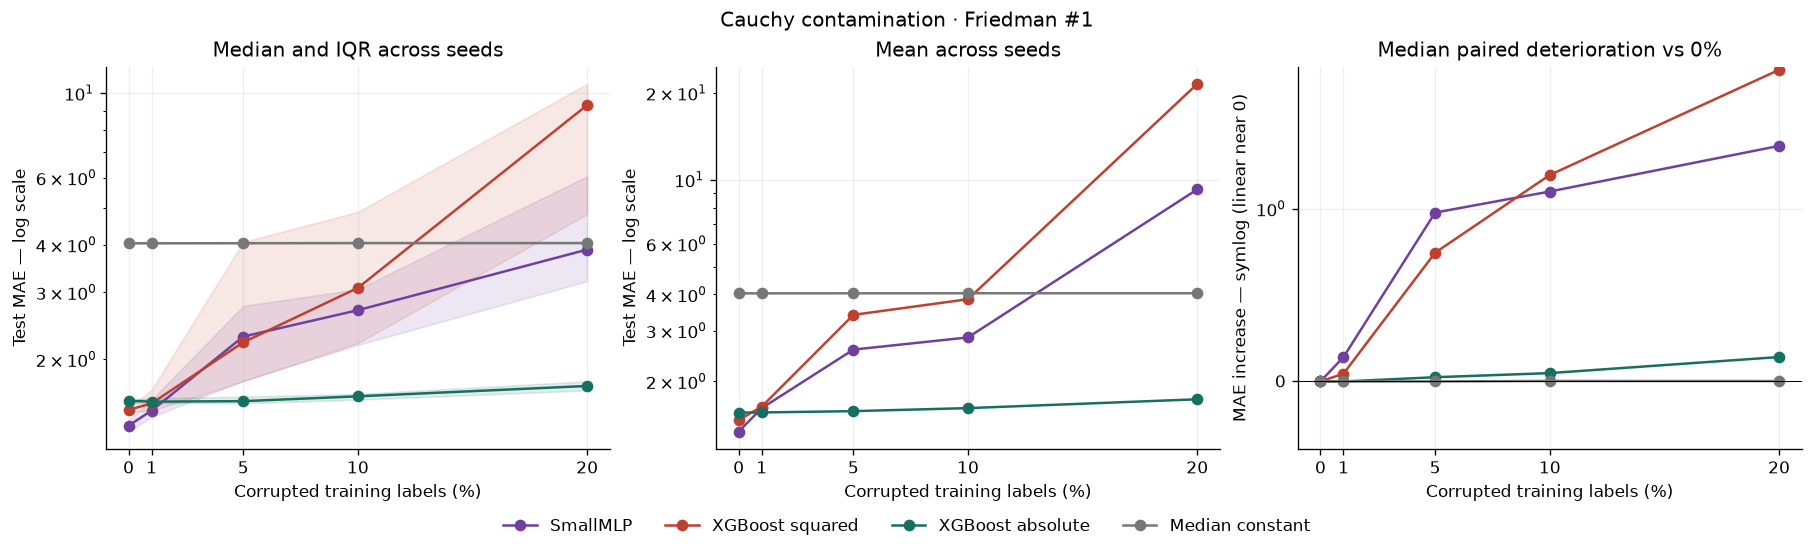

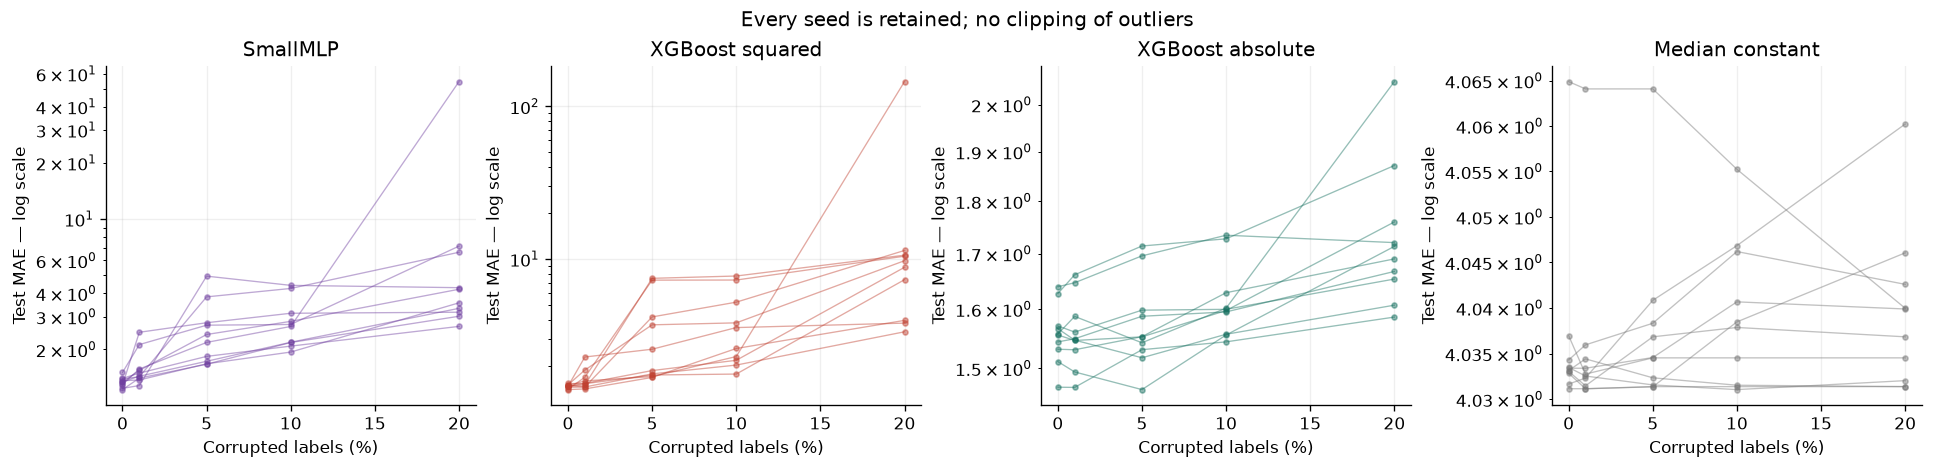

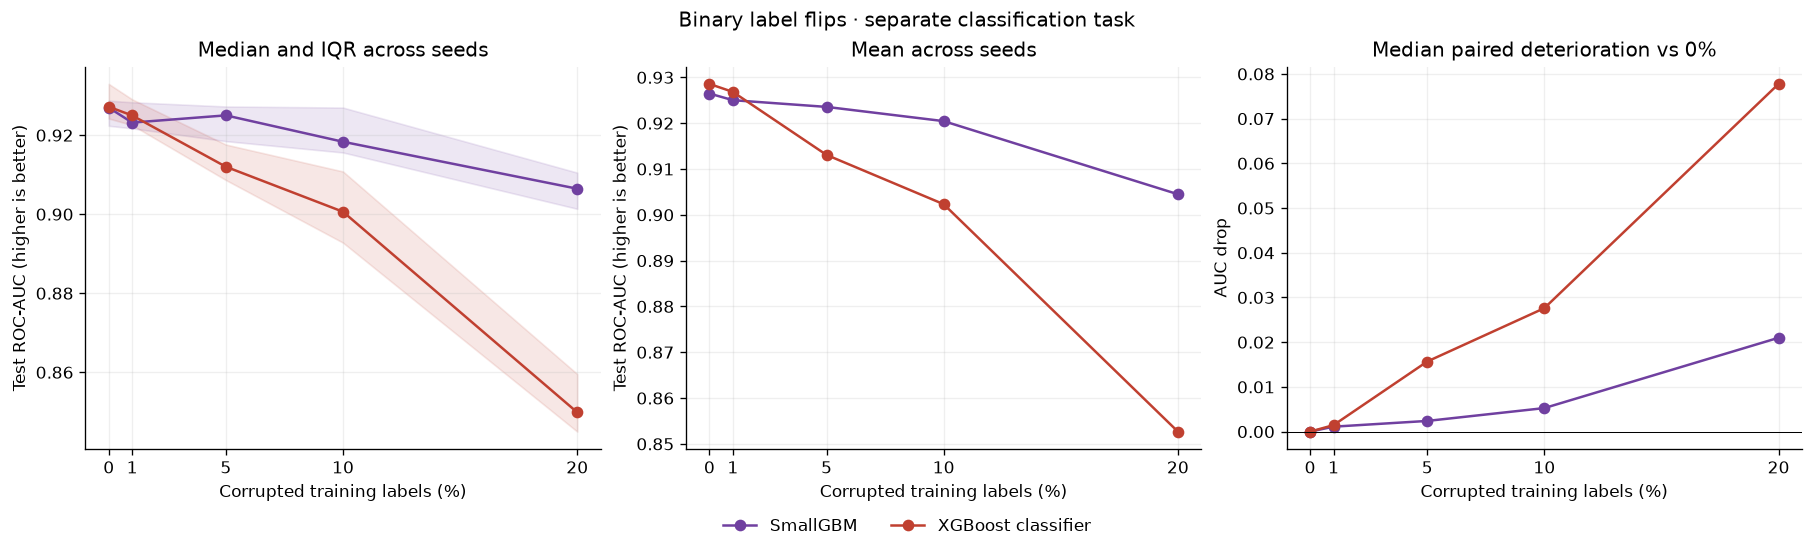

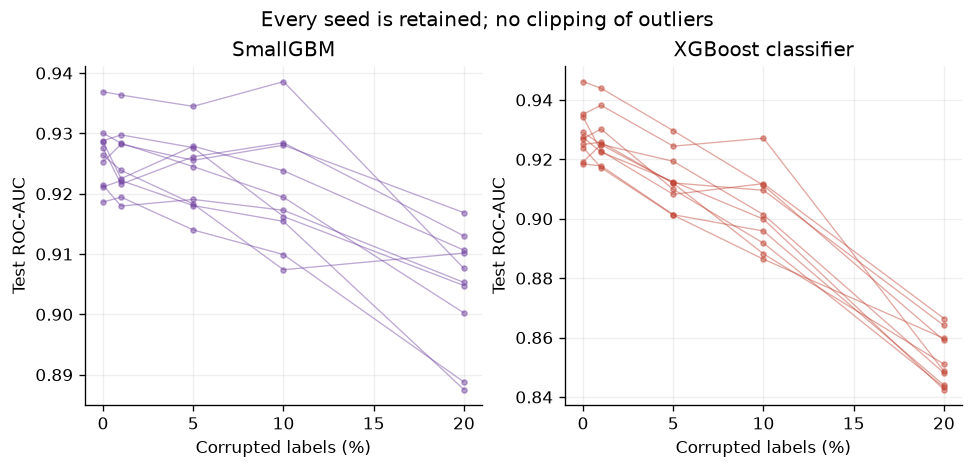

In [8]:
colors={"SmallMLP":"#7040a0","XGBoost squared":"#c04030","XGBoost absolute":"#167060","Median constant":"#777777","SmallGBM":"#7040a0","XGBoost classifier":"#c04030"}
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"figure.dpi":120})
def plot_results(task,models,metric,change):
    fig,ax=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
    for name in models:
        ss=sorted([s for s in summary if s["task"]==task and s["model"]==name],key=lambda s:s["corruption_pct"])
        xx=[s["corruption_pct"] for s in ss]
        mm=[np.nan if s["median"] is None else s["median"] for s in ss]
        ax[0].plot(xx,mm,"o-",label=name,color=colors[name])
        ax[0].fill_between(xx,[np.nan if s["q25"] is None else s["q25"] for s in ss],[np.nan if s["q75"] is None else s["q75"] for s in ss],color=colors[name],alpha=.12)
        ax[1].plot(xx,[np.nan if s["mean"] is None else s["mean"] for s in ss],"o-",color=colors[name])
        deltas=[]
        for pct in xx:
            vv=[r[change] for r in rows if r["task"]==task and r["model"]==name and r["corruption_pct"]==pct and r["status"]=="ok" and r[change] is not None]
            deltas.append(float(np.median(vv)) if vv else np.nan)
        ax[2].plot(xx,deltas,"o-",color=colors[name])
    ax[0].set_title("Median and IQR across seeds")
    ax[1].set_title("Mean across seeds")
    ax[2].set_title("Median paired deterioration vs 0%")
    for a in ax:
        a.set_xlabel("Corrupted training labels (%)");a.set_xticks([100*p for p in RATES]);a.grid(alpha=.2)
    for a in ax[:2]:a.set_ylabel("Test MAE (lower is better)" if task=="regression" else "Test ROC-AUC (higher is better)")
    ax[2].set_ylabel("MAE increase" if task=="regression" else "AUC drop")
    ax[2].axhline(0,color="black",lw=.6)
    if task=="regression":
        for a in ax[:2]:a.set_yscale("log");a.set_ylabel("Test MAE — log scale")
        ax[2].set_yscale("symlog",linthresh=1)
        ax[2].set_ylabel("MAE increase — symlog (linear near 0)")
    fig.legend(*ax[0].get_legend_handles_labels(),loc="outside lower center",ncol=min(4,len(models)),frameon=False)
    fig.suptitle("Cauchy contamination · Friedman #1" if task=="regression" else "Binary label flips · separate classification task")
    fig.savefig(OUT/f"{task}_summary.png",dpi=180,bbox_inches="tight")
    fig.savefig(OUT/f"{task}_summary.pdf",bbox_inches="tight")
    plt.show()
    fig,axes=plt.subplots(1,len(models),figsize=(4*len(models),3.8),squeeze=False,constrained_layout=True)
    for a,name in zip(axes[0],models):
        for seed in SEEDS:
            rr=sorted([r for r in rows if r["task"]==task and r["model"]==name and r["seed"]==seed and r["status"]=="ok"],key=lambda r:r["corruption_pct"])
            a.plot([r["corruption_pct"] for r in rr],[r[metric] for r in rr],"o-",lw=.8,alpha=.45,color=colors[name],markersize=3)
        a.set_title(name);a.set_xlabel("Corrupted labels (%)");a.grid(alpha=.2)
        if task=="regression":a.set_yscale("log");a.set_ylabel("Test MAE — log scale")
        else:a.set_ylabel("Test ROC-AUC")
    fig.suptitle("Every seed is retained; no clipping of outliers")
    fig.savefig(OUT/f"{task}_all_seeds.png",dpi=180,bbox_inches="tight");plt.show()
plot_results("regression",REG_MODELS,"mae","mae_delta")
if RUN_CLASSIFICATION:plot_results("classification",CLS_MODELS,"roc_auc","auc_drop")

## Scope and references
These are two synthetic tasks with repeated training samples and fixed test sets, not a multi-dataset study. The classification experiment uses label flips, not Cauchy noise. Conclusions apply to the tested implementations, settings, and corruption scale.

SmallMLP · SmallGBM · XGBoost objectives · Friedman #1

In [ ]:
expected_runs=len(SEEDS)*len(RATES)*(len(REG_MODELS)+len(CLS_MODELS))
assert len(rows)==expected_runs
assert len({(r['task'],r['seed'],r['corruption_pct'],r['model']) for r in rows})==expected_runs
failed=[r for r in rows if r['status']!='ok']
print(f"Completed {len(rows)} of {expected_runs}; failed fits: {len(failed)}.")
print("Results:",OUT)
if failed:print("Review the error column in runs.csv before comparing models.")

Completed 300 of 300; failed fits: 0.
Results: results/group13/20261116-103909-422844
